# Validating CoLoRe simulation for Quasar Auto and Quasar x CMB

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on
- The notebook uses the sources output from CoLoRe, i.e. quasars, to validate the simulation through the auto-spectrum and cross spectrum with CMB lensing.
- The kappa values can be found in `./data/...test_box/`, along with $C_{\ell}$ (and its associated errors), and a logarithmic rebinning run with `./scripts/rebin_cls_qq.py`, which is the one used in this notebook.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import camb
import healpy as hp

from scipy.stats import chi2
from scipy.optimize import minimize
from scipy.interpolate import CubicSpline
from scipy.integrate import quad, simpson
from scipy.constants import c
import sys
sys.path.append('../')

from py.rebinning import hybrid_bin_cls, merge_sources_catalogs
import json

plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'serif',
})

# Theory QSO clustering auto-spectrum $C_{\ell}^{qq}$

## setting up CAMB

In [ ]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [ ]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build CAMB results instance
    """

    # Convert to CAMB inputs

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # Initial CAMB params

    pars = camb.CAMBparams()
    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )
    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # Matter power settings

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    # note that to get CAMB's internal calculation accurate at the 1% level at L~2000,
    # need lens_potential_accuracy=2. Increase to 4 for accurate match to the Limber calculation here
    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_pk
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=True)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=False)

    # Final results
    results = camb.get_results(pars)

    return results

## manual Limber integral

In [92]:
def W_q(z, kernel_context, kernel_args):
    '''
    Quasar clustering kernel.
    '''

    # jacobian of transforming n(chi)=dN/dchi to n(z)=dN/dz, i.e. dchi/dz 
    c_kms = c * 1e-3
    Hz = kernel_context["Hz"]

    bz_interp = kernel_args["bz_interp"]
    nz_interp = kernel_args["nz_interp"]
    A_bias = kernel_args["A_bias"]

    if kernel_args["zlim_bin"] is None:
        return bias * ndensity * (Hz / c_kms)
    
    else:
        zmin_bin, zmax_bin = kernel_args["zlim_bin"]
        # evaluate bias and redshift distribution
        if zmin_bin < z < zmax_bin:
            bias = A_bias * bz_interp(z)
            ndensity = nz_interp(z)

            return bias * ndensity * (Hz / c_kms)
        else:
            return 0


In [93]:
def W_kappa(z, kernel_context, kernel_args):
    '''
    CMB lensing convergence kernel.
    '''

    chi = kernel_context["chi"]
    chi_source = kernel_context["chi_source"]
    H0, om = kernel_context["cosmo_params"]

    # geometry
    a = 1.0 / (1.0 + z)
    c_kms = c * 1e-3

    # kernel prefactor
    W_prefactor = 1.5 * (H0 / c_kms)**2 * om * (chi_source - chi) / chi_source
    W_geom = chi / a

    return W_prefactor * W_geom

In [94]:
def limber(
    z,
    ell,
    kmax,
    kernel1,
    kernel2,
    kernel1_args,
    kernel2_args,
    kernel_context,
    pk_interp,
    kp,
):
    '''
    General Limber integrand.
    '''

    # getting the CAMB results object
    results = kernel_context["results"]

    # chi(z) and wavenumber of Limber approximation and 
    chi = results.comoving_radial_distance(z)
    k = (ell + 0.5) / chi

    # jacobian dchi/dz of the transformation integrating over z instead of chi
    c_kms = c * 1e-3
    Hz = results.hubble_parameter(z)
    kernel_context["Hz"] = Hz
    kernel_context["chi"] = chi

    # avoid extrapolation of CAMB kmax and small scales
    if 1e-4 < k < kmax:

        # tracer kernels
        W1 = kernel1(z, kernel_context, kernel1_args)
        W2 = kernel2(z, kernel_context, kernel2_args)
        # matter power spectrum
        pk = pk_interp.P(z, k, grid=False)
        # smoothing
        smooth = np.exp(-(k / kp)**2)

        return (
            (c_kms / Hz)
            * ((W1 * W2) / chi**2)
            * pk
            * smooth
        )

    else:
        return 0

In [95]:
def get_limber_cls(
    params_path,
    z_pk,
    kernel1,
    kernel2,
    kernel1_args,
    kernel2_args,
    nside,
    kmax=100,
    lmin=2,
    lmax=2500,
    kp=None, # default fitted smoothing scale in (1/Mpc)
):
    '''
    Compute the angular qq/kq power spectra using the Limber approximation.
    '''

    # get cosmological parameters
    cosmo_dict = load_cosmology(params_path)
    z_max = cosmo_dict["z_max"]

    # get CAMB results
    results_lin = get_camb_results(
        cosmo_dict=cosmo_dict,
        z_pk=z_pk,
        kmax=kmax,
        lmax=lmax,
        nonlinear=False
    )

    # get matter power spectrum interpolator
    pk_interp_lin = results_lin.get_matter_power_interpolator(
        nonlinear=False,
        hubble_units=False,
        k_hunit=False,
        var1='delta_tot',
        var2='delta_tot'
    )

    # compute source comoving distance for CMB lensing
    z_star = results_lin.get_derived_params()['zstar']
    chi_star = results_lin.comoving_radial_distance(z_star)

    # cosmological parameters needed by kernels
    H0 = cosmo_dict["h"] * 100
    om = cosmo_dict["omega_M"]

    # shared kernel context
    chi_source = chi_star
    kernel_context = {
        "results": results_lin,
        "chi_source": chi_source,
        "cosmo_params": (H0, om),
    }

    # multipoles
    ells = np.arange(lmin, lmax + 1)

    # store cls
    cls = np.zeros(len(ells))

    # integrate Limber approximation
    for i, ell in enumerate(ells):

        cls[i] = quad(
            limber,
            1e-4,
            z_max,
            args=(
                ell,
                kmax,
                kernel1,
                kernel2,
                kernel1_args,
                kernel2_args,
                kernel_context,
                pk_interp_lin,
                kp,
            )
        )[0]

    # smooth with healpix pixel window function
    lmax_map = nside * 3 - 1
    pixwin = hp.pixwin(
        nside,
        lmax=lmax_map
    )
    pixwin = pixwin[lmin:]

    if lmax_map > lmax:
        cls_smoothed = cls * pixwin[:len(cls)]**2
    else:
        cls_smoothed = cls[:len(pixwin)] * pixwin**2

    return {
        "ells": np.arange(lmin, len(cls_smoothed) + lmin),
        "cls": cls_smoothed,
    }

In [96]:
# set the redshift range for the boltzmann solver
zmin, zmax = 0, 1100
nz = 200
z_pk = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1
z_pk = z_pk[::-1] # reverse to have higher redshift first for better interpolation at high z
lmin, lmax = 2, 2500

In [97]:
# load the quasar catalogs, quasar bias and redshift distribution, and create interpolators for them
ra, dec, z = merge_sources_catalogs('../data/third_test_box/quasars/')
z_bz, bz = np.loadtxt('../data/colore_files/Bz_qso_G18.txt', unpack=True)
z_nz_input, nz_input = np.loadtxt('../data/colore_files/Nz_qso_130618_2_colore1_hZs.txt', unpack=True)
fsky = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2
nz_input = nz_input * fsky
nz_interp_input = CubicSpline(z_nz_input, nz_input, extrapolate=False)
bz_interp = CubicSpline(z_bz, bz, extrapolate=False)

Merged 64 catalogs from ../data/third_test_box/quasars/ into a single catalog with 12286278 quasars.


## Cross-check input n(z) with output CoLoRe n(z)

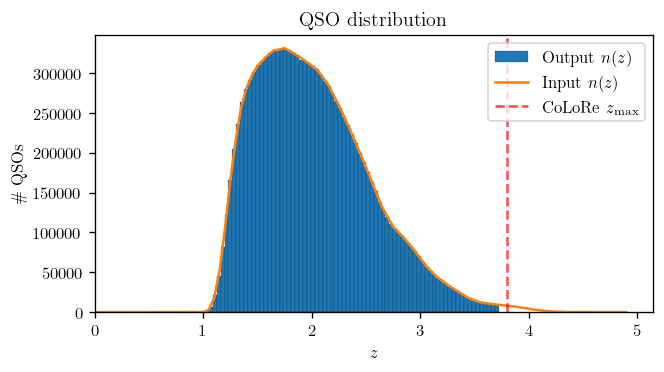

In [98]:
nbins = 100  # binning of the colore n(z)
plt.figure(figsize=(6,3), dpi=120)
nz_output, z_nz_edges = plt.hist(z, density=False, bins=nbins, label=r'Output $n(z)$', edgecolor='k', linewidth=0.1)[:2]
zbin_width = np.diff(z_nz_edges)[0]  # redshift bin width 
plt.plot(z_nz_input, nz_interp_input(z_nz_input)*zbin_width, label=r'Input $n(z)$')
plt.axvline(x=3.8, color='r', linestyle='--', alpha=0.7, label=r'CoLoRe $z_{\rm max}$')
plt.xlim(0)
plt.xlabel(r'$z$')
plt.ylabel(r'$\#$ QSOs')
plt.title('QSO distribution')
plt.legend()
plt.show()

In [99]:
z_nz_output = (z_nz_edges[:-1] + z_nz_edges[1:]) / 2  # get the bins middle points
norm = simpson(nz_output, z_nz_output)  # normalize the distribution just in case
nz_interp_output = CubicSpline(z_nz_output, nz_output/norm, extrapolate=True)  # create the n(z) interpolator for the theory

## Compute the theory Cls

In [100]:
# get the limber cls for the last box
nside_qq = 4096  # this nside has to match the one used to generate the colore Cls in the script
nside_kq = 4096  # this nside has to match the one used to generate the colore Cls in the script
params_path = '../data/third_test_box/cosmo_params.json'

results_qq_box3 = get_limber_cls(
    params_path=params_path,
    z_pk=z_pk,
    kernel1=W_q,
    kernel2=W_q,
    kernel1_args={
        "bz_interp": bz_interp,
        "nz_interp": nz_interp_output,
        "A_bias": 0.711
    },
    kernel2_args={
        "bz_interp": bz_interp,
        "nz_interp": nz_interp_output,
        "A_bias": 0.711
    },
    nside=nside_qq,
    kp=0.405 # default fitted smoothing scale in (1/Mpc)
)

results_kq_box3 = get_limber_cls(
    params_path=params_path,
    z_pk=z_pk,
    kernel1=W_kappa,
    kernel2=W_q,
    kernel1_args={},
    kernel2_args={
        "bz_interp": bz_interp,
        "nz_interp": nz_interp_output,
        "A_bias": 0.688,
        "zlim_bin": [0, 1.5]
    },
    nside=nside_kq,
    kp=0.246 # default fitted smoothing scale in (1/Mpc)
)

# extract the relevant results for the last box
keys = ['ells', 'cls']
ells_qq, cl_qq_lin_box3 = [results_qq_box3[k] for k in keys]
ells_kq, cl_kq_lin_box3 = [results_kq_box3[k] for k in keys]

KeyError: 'zlim_bin'

# CoLoRe simulation auto-spectrum $C_{\ell}^{q q}$

In [ ]:
def get_colore_cls(box_filename):
    '''
    Load the Colore kappa power spectrum from a text file
    '''

    # load the data from the .npz file
    data = np.load(box_filename)
    ells, cl, err = data['ells'], data['cls'], data['err']

    return ells, cl, err

In [ ]:
ells_qq_colore, cl_qq_colore, err_qq_colore = get_colore_cls('../data/third_test_box/quasars/cl_qq_log.npz')
ells_kq_colore, cl_kq_colore, err_kq_colore = get_colore_cls('../data/third_test_box/quasars/cl_kq_log.npz')
nbins_qq = ells_qq_colore.size
nbins_kq = ells_kq_colore.size

# filter out NaN values which may arise from empty bins in the rebinning process
mask_qq = np.isfinite(ells_qq_colore)
mask_kq = np.isfinite(ells_qq_colore)
ells_colore, cl_qq_colore, err_qq_colore = [arr[mask_qq] for arr in [ells_qq_colore, cl_qq_colore, err_qq_colore]]
ells_colore, cl_kq_colore, err_kq_colore = [arr[mask_kq] for arr in [ells_kq_colore, cl_kq_colore, err_kq_colore]]

# determine the lmin and lmax from the Colore data to ensure consistent binning for residuals
lmin_colore = lmin
lmax_qq_colore = np.load(f'../data/third_test_box/quasars/cl_qq.npz')['ells'].max()
lmax_kq_colore = np.load(f'../data/third_test_box/quasars/cl_kq.npz')['ells'].max()

In [ ]:
# rebin the CAMB linear and non-linear cls to match the number of bins in the Colore data for residuals
cl_qq_lin_box3_rebin = hybrid_bin_cls(ells_qq, cl_qq_lin_box3, nbins=nbins_qq, ell_min=lmin_colore, ell_max=lmax_qq_colore)[1]
cl_kq_lin_box3_rebin = hybrid_bin_cls(ells_kq, cl_kq_lin_box3, nbins=nbins_kq, ell_min=lmin_colore, ell_max=lmax_kq_colore)[1]

# filter out NaN values which may arise from empty bins in the rebinning process
cl_qq_lin_box3_rebin = cl_qq_lin_box3_rebin[mask_qq]
cl_kq_lin_box3_rebin = cl_kq_lin_box3_rebin[mask_kq]

# plotting

## latest CoLoRe box analysis and $\chi^2$ test

In [ ]:
def plot_cls_qq_comparison(ells_colore, cl_qq_colore, err_qq_colore, ells, cl_qq_lin, cl_qq_lin_rebin, box_label):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), height_ratios=[2.5, 1], dpi=120, sharex=True)

    # compute the reduced chi-squared between the rebinned linear limber and the rebinned CoLoRe cls
    chi2 = np.sum((cl_qq_colore - cl_qq_lin_rebin)**2 / err_qq_colore**2)
    chi2_nu = chi2 / (len(ells_colore))

    # plot the rebinned CoLoRe Cls with error bars
    ax1.errorbar(ells_colore, cl_qq_colore, yerr=err_qq_colore, elinewidth=0.7, capsize=1.0, fmt='C0.', markersize=5.0, 
                 label=rf'CoLoRe_{box_label} (shot-noise subtraction)')
    ax1.scatter(0, 0 , s=0, label=rf'$\chi^2_\nu = {chi2_nu:.2f}$')

    # manual limber integration full redshift
    ax1.plot(ells, cl_qq_lin, c='C0', ls='-', label=rf'Limber_linear')

    # shade most sensitive region to the analysis
    lmin_fit, lmax_fit = 20, 1000
    ax1.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.15, label='Most sensitive region')

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlim(1.5, 3000)
    ax1.set_ylabel(r'$C_{L}^{qq}$')
    ax1.legend()

    # plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
    rel_error = (cl_qq_colore - cl_qq_lin_rebin) / cl_qq_lin_rebin
    rel_error_err = err_qq_colore / cl_qq_lin_rebin

    # split the relative error plot into two panels for better visibility of low and high multipoles
    l_lim = ells_colore.max()

    # plot the relative error for low multipoles in the main panel
    ax2.errorbar(ells_colore[ells_colore < l_lim], rel_error[ells_colore < l_lim], 
                yerr=rel_error_err[ells_colore < l_lim], capsize=1.0, elinewidth=0.7, fmt='C0.', markersize=5.0)
    ax2.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.15, label='Most sensitive region')
    ax2.axhline(0, c='k', ls='--', lw=0.7)
    ax2.set_ylim(-1.0, 1.0)
    ax2.set_xscale('log')
    ax2.set_xlabel(r'Multipole $L$')
    ax2.set_ylabel(rf'rel. error')

    fig.suptitle('QSO auto-spectrum: Theory vs. CoLoRe box', y=0.93)

    fig.savefig(f'plots/cls_qq_{box_label}.png', bbox_inches='tight')
    fig.savefig(f'plots/cls_qq_{box_label}.pdf', bbox_inches='tight')
    plt.show()

In [ ]:
def plot_cls_kq_comparison(ells_colore, cl_kq_colore, err_kq_colore, ells, cl_kq_lin, cl_kq_lin_rebin, box_label):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), height_ratios=[2.5, 1], dpi=120, sharex=True)

    # compute the reduced chi-squared between the rebinned linear limber and the rebinned CoLoRe cls
    chi2 = np.sum((cl_kq_colore - cl_kq_lin_rebin)**2 / err_kq_colore**2)
    chi2_nu = chi2 / (len(ells_colore))

    # plot the rebinned CoLoRe Cls with error bars
    ax1.errorbar(ells_colore, cl_kq_colore, yerr=err_kq_colore, elinewidth=0.7, capsize=1.0, fmt='C0.', markersize=5.0, 
                 label=rf'CoLoRe_{box_label} (shot-noise subtraction)')
    ax1.scatter(0, 0 , s=0, label=rf'$\chi^2_\nu = {chi2_nu:.2f}$')

    # manual limber integration full redshift
    ax1.plot(ells, cl_kq_lin, c='C0', ls='-', label=rf'Limber_linear')

    # shade most sensitive region to the analysis
    lmin_fit, lmax_fit = 20, 1000
    ax1.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.15, label='Most sensitive region')

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlim(1.5, 3000)
    ax1.set_ylabel(r'$C_{L}^{kq}$')
    ax1.legend()

    # plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
    rel_error = (cl_kq_colore - cl_kq_lin_rebin) / cl_kq_lin_rebin
    rel_error_err = err_kq_colore / cl_kq_lin_rebin

    # split the relative error plot into two panels for better visibility of low and high multipoles
    l_lim = ells_colore.max()

    # plot the relative error for low multipoles in the main panel
    ax2.errorbar(ells_colore[ells_colore < l_lim], rel_error[ells_colore < l_lim], 
                yerr=rel_error_err[ells_colore < l_lim], capsize=1.0, elinewidth=0.7, fmt='C0.', markersize=5.0)
    ax2.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.15, label='Most sensitive region')
    ax2.axhline(0, c='k', ls='--', lw=0.7)
    ax2.set_ylim(-1.0, 1.0)
    ax2.set_xscale('log')
    ax2.set_xlabel(r'Multipole $L$')
    ax2.set_ylabel(rf'rel. error')

    fig.suptitle(r'CMB lensing $\times$ QSO spectrum: Theory vs. CoLoRe box', y=0.93)

    fig.savefig(f'plots/cls_kq_{box_label}.png', bbox_inches='tight')
    fig.savefig(f'plots/cls_kq_{box_label}.pdf', bbox_inches='tight')
    plt.show()

In [ ]:
plot_cls_qq_comparison(ells_qq_colore, cl_qq_colore, err_qq_colore, ells_qq, cl_qq_lin_box3, cl_qq_lin_box3_rebin, box_label='third_box')
plot_cls_kq_comparison(ells_kq_colore, cl_kq_colore, err_kq_colore, ells_kq, cl_kq_lin_box3, cl_kq_lin_box3_rebin, box_label='third_box')  

In [ ]:
def plot_cumulative_chi2(ells_colore, cl_xx_colore, err_xx, cl_xx_lin_rebin, box_label, xx_type='qq'):

    # compute the cumulative chi-square and p-values for each multipole bin
    chi2_per_bin = ((cl_xx_colore - cl_xx_lin_rebin) / err_xx)**2
    cumulative_chi2 = np.nancumsum(chi2_per_bin)
    cumulative_dof = np.arange(1, len(cumulative_chi2) + 1)
    p_values = 1 - chi2.cdf(cumulative_chi2, df=cumulative_dof)

    # Plotting the cumulative chi-square
    fig, ax1 = plt.subplots(figsize=(6, 4), dpi=120)
    ax2 = ax1.twinx()  # Create a second y-axis for p-values

    # Plot your cumulative chi-square
    ax1.plot(ells_colore, cumulative_chi2, marker='.', linestyle='-', color='C0', label=rf'Cumulative $\chi^2$ ({box_label})')
    ax2.plot(ells_colore, p_values, marker='.', linestyle='-', color='C1', label=r'Cumulative $p$-value', alpha=0.3)

    # Plot the expected theoretical baseline (Expected chi^2 = dof)
    ax1.plot(ells_colore, cumulative_dof, linestyle='--', color='black', label=r'Expected $\chi^2$ (Perfect Fit)')

    # Formatting the plot
    ax1.set_xscale('log')
    ax1.set_yscale('linear') # A log scale on the y-axis is highly recommended since the max value is ~8000
    ax1.set_xlabel('Multipole $L$')
    ax1.set_ylabel(r'Cumulative $\chi^2$')
    ax2.set_ylabel(r'Cumulative $p$-value')
    ax1.set_title(r'Cumulative $\chi^2$ vs. Multipole $L$')
    ax1.legend(loc='upper left')
    ax2.legend(loc='upper right')

    fig.savefig(f'plots/cls_{xx_type}_{box_label}_cumulative_chi2.png', bbox_inches='tight')  
    fig.savefig(f'plots/cls_{xx_type}_{box_label}_cumulative_chi2.pdf', bbox_inches='tight')  

    plt.show()

In [ ]:
plot_cumulative_chi2(ells_qq_colore, cl_qq_colore, err_qq_colore, cl_qq_lin_box3_rebin, box_label='third_box', xx_type='qq')
plot_cumulative_chi2(ells_kq_colore, cl_kq_colore, err_kq_colore, cl_kq_lin_box3_rebin, box_label='third_box', xx_type='kq')

# fitting $k_p$ and $A_{\rm bias}$

One can see that for $20 \leq \ell \leq 1000$, the ratio between data and theory auto-spectrum is approximately constant. \
This is due to a mismatch between the input quasar bias $b(z)$ and output quasar bias $b(z)$ from the simulation. 
- To solve this, we can fit for a redshift-independent bias amplitude so that $B(z) = A_{\rm bias} * b(z)$.
- Moreover, we can fit at the same time for the $k_p$ parameter smoothing out the theory PK. \
This parameter doesn't have to be the same as for CMB lensing. \
Thi is due to additional processes that sources (like quasars), unlike CMB lensing, undergo in CoLoRe runs.

In [ ]:
bratio = cl_qq_colore / cl_qq_lin_box3_rebin
plt.figure(figsize=(6,4), dpi=120)
plt.plot(ells_colore, bratio, marker='.', linestyle='-', label=r'Input/output $A_{\rm bias}$')
plt.axvspan(20, 1000, color='gray', alpha=0.3, label='Most sensitive region')
plt.xlim(2, 3000)
plt.xscale('log')
plt.xlabel(r'Multipole L')
plt.ylabel(r'$C_L^{qq, \rm data} \ / \ C_L^{qq, \rm theory}$')
plt.title('Data/theory auto-spectrum ratio')
plt.legend()
plt.show()

In [ ]:
def get_fitting_cls(
    kp,
    params_path,
    box_path,
    z_pk,
    nside,
    lmin_fit,
    lmax_fit,
    kernel1,
    kernel2,
    kernel1_args,
    kernel2_args,
    kmax=100.0,
    nbins=30,
):
    '''
    Compute rebinned data and theory Cls for fitting.
    '''

    # load and rebin data
    ells_data, cls_data, err_data = get_colore_cls(box_path)
    _, cls_data, err_data = hybrid_bin_cls(
        ells_data,
        cls_data,
        err_data,
        nbins=nbins,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

    # compute theory
    results = get_limber_cls(
        params_path=params_path,
        z_pk=z_pk,
        kernel1=kernel1,
        kernel2=kernel2,
        kernel1_args=kernel1_args,
        kernel2_args=kernel2_args,
        nside=nside,
        kp=kp,
        kmax=kmax,
        lmin=2,
        lmax=2500,
    )

    _, cls_theory, _ = hybrid_bin_cls(
        results["ells"],
        results["cls"],
        nbins=nbins,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

    return cls_data, cls_theory, err_data

In [ ]:
def get_chi2(
    params,
    params_path,
    box_path,
    z_pk,
    nside,
    lmin_fit,
    lmax_fit,
    kernel1,
    kernel2,
    kernel1_args,
    kernel2_args,
):
    '''
    Reduced chi-squared for qq or qk fitting.
    '''

    # fitting parameters
    kp, A_bias = params

    # update bias amplitude
    kernel2_args["A_bias"] = A_bias

    if kernel2 == kernel1:
        kernel1_args["A_bias"] = A_bias

    # compute data and theory
    cls_data, cls_theory, err_data = get_fitting_cls(
        kp=kp,
        params_path=params_path,
        box_path=box_path,
        z_pk=z_pk,
        nside=nside,
        lmin_fit=lmin_fit,
        lmax_fit=lmax_fit,
        kernel1=kernel1,
        kernel2=kernel2,
        kernel1_args=kernel1_args,
        kernel2_args=kernel2_args,
    )

    # remove invalid values
    mask = (
        np.isfinite(cls_data)
        & np.isfinite(cls_theory)
        & np.isfinite(err_data)
        & (err_data > 0)
    )

    cls_data = cls_data[mask]
    cls_theory = cls_theory[mask]
    err_data = err_data[mask]

    # get chi2 statistic
    chi2 = np.sum(
        ((cls_data - cls_theory) / err_data)**2
    )

    return chi2 / (len(cls_data) - 2)  # fitting 2 parameters

## QSO auto fit

In [ ]:
lmin_fit = 20
lmax_fit = 1000

params_path = '../data/third_test_box/cosmo_params.json'
box_path = '../data/third_test_box/quasars/cl_qq.npz'

result = minimize(
    get_chi2,
    x0=[0.3, 0.7],
    bounds=[(0.1, 1.0), (0.1, 2.0)],
    method="L-BFGS-B",
    args=(
        params_path,
        box_path,
        z_pk,
        nside_qq,
        lmin_fit,
        lmax_fit,
        W_q,
        W_q,
        {
            "bz_interp": bz_interp,
            "nz_interp": nz_interp_output,
        },
        {
            "bz_interp": bz_interp,
            "nz_interp": nz_interp_output,
        },
    )
)

best_kp, best_Abias = result.x
cov = result.hess_inv.todense()
errors = np.sqrt(np.diag(cov))
chi2_best = result.fun

In [ ]:
print(f"Best-fit k_p: {best_kp:.3f} +/- {errors[0]:.3f} 1/Mpc")
print(f"Best-fit A_bias: {best_Abias:.3f} +/- {errors[1]:.3f}")
print(f"Reduced chi-squared at best-fit k_p: {chi2_best:.3f}")

## CMB x QSO cross fit

In [ ]:
lmin_fit = 20
lmax_fit = 1000

params_path = '../data/third_test_box/cosmo_params.json'
box_path = '../data/third_test_box/quasars/cl_kq.npz'

result = minimize(
    get_chi2,
    x0=[0.3, 0.722],
    bounds=[(0.1, 1.0), (0.1, 2.0)],
    method="L-BFGS-B",
    args=(
        params_path,
        box_path,
        z_pk,
        nside_qq,
        lmin_fit,
        lmax_fit,
        W_kappa,
        W_q,
        {},
        {
            "bz_interp": bz_interp,
            "nz_interp": nz_interp_output,
        },
    )
)


best_kp, best_Abias = result.x
cov = result.hess_inv.todense()
errors = np.sqrt(np.diag(cov))
chi2_best = result.fun

In [ ]:
print(f"Best-fit k_p: {best_kp:.3f} +/- {errors[0]:.3f} 1/Mpc")
print(f"Best-fit A_bias: {best_Abias:.3f} +/- {errors[1]:.3f}")
print(f"Reduced chi-squared at best-fit k_p: {chi2_best:.3f}")

## tomographic bin fit